# 7. Componente temporal (2.6)

Obligatorio porque el dataset trae la **fecha y hora del pedido**. Se valida la variable
temporal, se visualiza la serie y su estacionalidad, se descompone (STL), se prueba la
estacionariedad (ADF y KPSS), se mide la dependencia temporal (ACF, PACF, correlación
cruzada), se buscan cambios de régimen y efectos de calendario y se mide la deriva
entre periodos. **Solo entrenamiento** (pedidos hasta el inicio del *gap*).

Se usan las herramientas de series de tiempo de `statsmodels` {cite}`seabold_2010` siguiendo
{cite}`hyndman_2021`. La unidad es el pedido (evento irregular), así que para el análisis de series se
**agregan** las líneas por día: número de líneas y proporción de entregas tardías.

In [1]:
from pathlib import Path
import re, sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display

project_root = Path.cwd().resolve()
while not (project_root / "_config.yml").exists():
    if project_root.parent == project_root:
        raise FileNotFoundError("No se encontró _config.yml. Ejecuta el notebook dentro de la carpeta del libro.")
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

for _folder in ("tables", "figures"):          # se crean si no existen
    (project_root / _folder).mkdir(exist_ok=True)

from src.project_utils import *

configure_plots()
pd.set_option("display.max_columns", 80)
pd.set_option("display.width", 170)
pd.set_option("display.max_colwidth", 70)
TABLES = project_root / "tables"

def md_out(text):
    display(Markdown(text))

from scipy import stats
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller, kpss, ccf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from pandas.tseries.holiday import USFederalHolidayCalendar
warnings.filterwarnings("ignore", message=".*InterpolationWarning.*")
from statsmodels.tools.sm_exceptions import InterpolationWarning
warnings.simplefilter("ignore", InterpolationWarning)
train = load_train()
y = train[TARGET]
d = train[DATE_COL]
diario = train.groupby(d.dt.normalize()).agg(lineas=(TARGET, "size"), pedidos=(ORDER_COL, "nunique"), tardias=(TARGET, "sum"))
diario = diario.asfreq("D")
diario["tasa"] = diario["tardias"] / diario["lineas"]

## Validación de la variable temporal

In [2]:
raw_txt = pd.read_csv(ensure_data(), encoding=ENCODING, usecols=["order date (DateOrders)"])["order date (DateOrders)"]
parsed = pd.to_datetime(raw_txt, format="%m/%d/%Y %H:%M", errors="coerce")
pedidos_t = train.groupby(ORDER_COL)[DATE_COL].first().sort_values()
dif_min = pedidos_t.diff().dt.total_seconds().div(60).dropna()
val = pd.DataFrame([
    ("Formato original", "texto «M/D/AAAA H:MM» (sin segundos)"),
    ("Valores que no se pueden interpretar como fecha (todo el archivo)", int(parsed.isna().sum())),
    ("Zona horaria", "no informada; se asume hora local única (sin conversión)"),
    ("Primer pedido de entrenamiento", f"{d.min():%Y-%m-%d %H:%M}"),
    ("Último pedido de entrenamiento", f"{d.max():%Y-%m-%d %H:%M}"),
    ("Días del periodo", len(diario)),
    ("Días sin pedidos (huecos)", int(diario["lineas"].isna().sum())),
    ("Frecuencia", "irregular (eventos); se agrega por día"),
    ("Mediana de minutos entre pedidos consecutivos", es(dif_min.median(), 1)),
    ("Pedidos con la misma marca de tiempo que otro pedido", es(int(pedidos_t.duplicated().sum()), 0)),
    ("Líneas con marca duplicada (líneas de un mismo pedido, esperado)", es(int(d.duplicated().sum()), 0)),
], columns=["comprobación", "resultado"])
val.to_csv(TABLES / "validacion_temporal.csv", index=False)
display(val)
md_out(f"Los minutos entre pedidos consecutivos toman pocos valores: {', '.join(f'{int(k)} min ({es(int(v), 0)} veces)' for k, v in dif_min.value_counts().head(4).items())}. "
       "La llegada de pedidos es **casi determinística** (un pedido cada ~20 minutos), señal de que los datos son simulados.")

,comprobación,resultado
0,Formato original,texto «M/D/AAAA H:MM» (sin segundos)
1,Valores que no se pueden interpretar como fecha (todo el archivo),0
2,Zona horaria,no informada; se asume hora local única (sin conversión)
3,Primer pedido de entrenamiento,2015-01-01 00:00
4,Último pedido de entrenamiento,2017-04-14 23:42
5,Días del periodo,835
6,Días sin pedidos (huecos),0
7,Frecuencia,irregular (eventos); se agrega por día
8,Mediana de minutos entre pedidos consecutivos,"21,0"
9,Pedidos con la misma marca de tiempo que otro pedido,0


Los minutos entre pedidos consecutivos toman pocos valores: 21 min (39.034 veces), 42 min (6.255 veces), 63 min (1.027 veces), 22 min (807 veces). La llegada de pedidos es **casi determinística** (un pedido cada ~20 minutos), señal de que los datos son simulados.

**Interpretación.** No hay fechas inválidas ni huecos: todos los días tienen pedidos. Las
marcas duplicadas son las líneas de un mismo pedido (esperado). El ritmo de llegada es
casi constante, lo que anticipa poca estacionalidad en el volumen.

## Visualización: serie completa y agregaciones

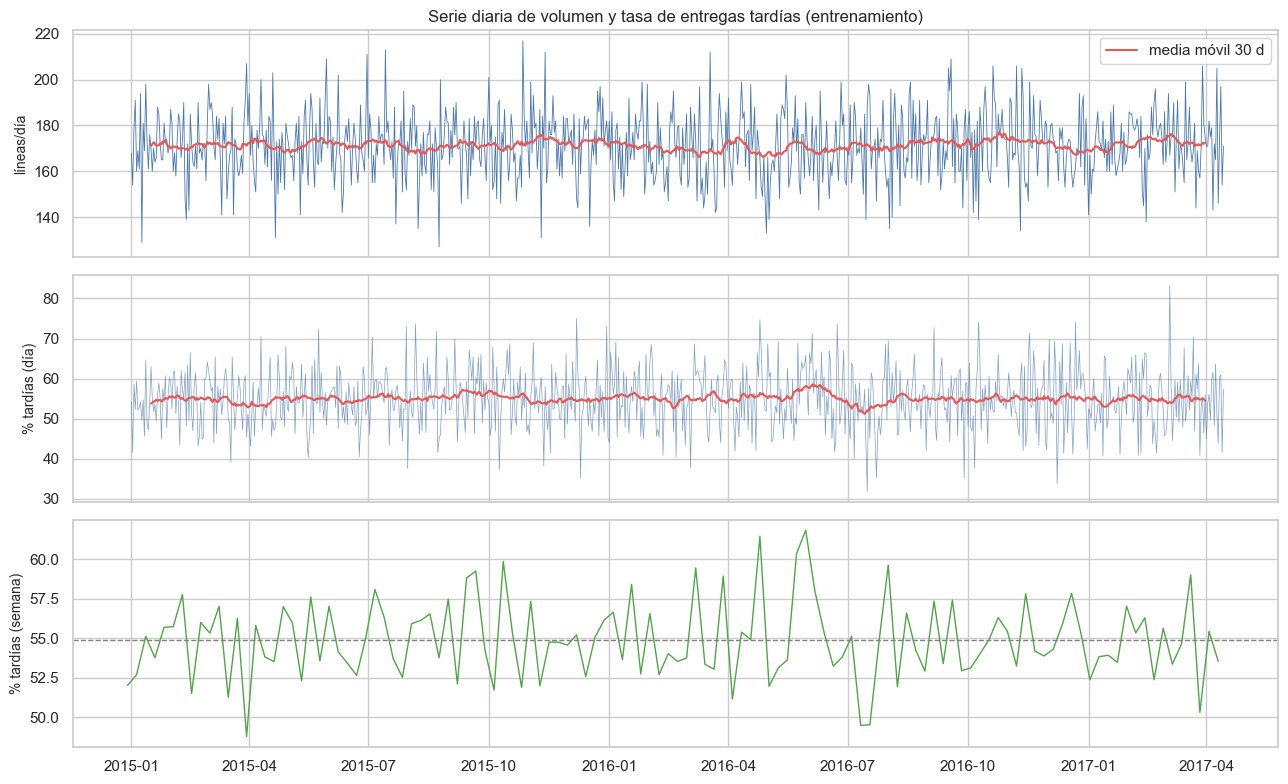

In [3]:
fig, axes = plt.subplots(3, 1, figsize=(13, 8), sharex=True)
axes[0].plot(diario.index, diario["lineas"], lw=0.6, color="#4c78a8"); axes[0].set_ylabel("líneas/día")
axes[0].plot(diario["lineas"].rolling(30, center=True).mean(), color="#e45756", lw=1.5, label="media móvil 30 d"); axes[0].legend()
axes[1].plot(diario.index, 100 * diario["tasa"], lw=0.5, color="#4c78a8", alpha=0.7)
axes[1].plot(100 * diario["tasa"].rolling(30, center=True).mean(), color="#e45756", lw=1.5); axes[1].set_ylabel("% tardías (día)")
sem = train.groupby(d.dt.to_period("W"))[TARGET].mean()
axes[2].plot(sem.index.to_timestamp(), 100 * sem.values, color="#54a24b", lw=1); axes[2].set_ylabel("% tardías (semana)")
axes[2].axhline(100 * y.mean(), color="gray", ls="--", lw=1)
axes[0].set_title("Serie diaria de volumen y tasa de entregas tardías (entrenamiento)")
plt.tight_layout(); save_figure(fig, "07_serie_diaria.png"); plt.show()

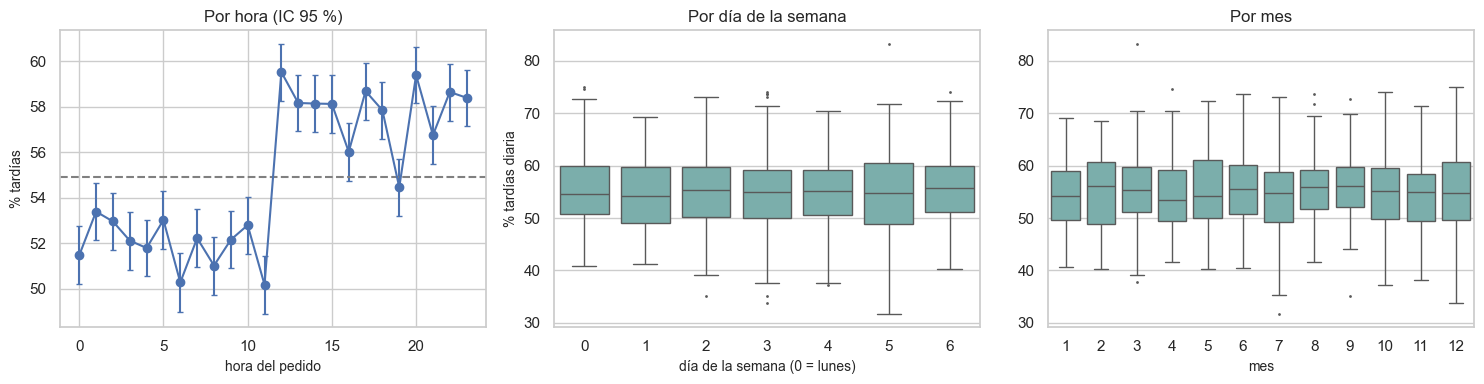

- Hora: χ² = 586,8, p = 2.7e-109, V de Cramér = 0,063.
- Día de la semana (tasa diaria): Kruskal-Wallis H = 1,80, p = 0.937.
- Mes (tasa diaria): Kruskal-Wallis H = 4,78, p = 0.941.

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
h = rate_table(train["order_hour"], y, min_n=1).assign(h=lambda t: t["categoria"].astype(int)).sort_values("h")
axes[0].errorbar(h["h"], 100 * h["tasa"], yerr=[100 * (h["tasa"] - h["ic_inf"]), 100 * (h["ic_sup"] - h["tasa"])], fmt="o-", capsize=2)
axes[0].axhline(100 * y.mean(), color="gray", ls="--"); axes[0].set_xlabel("hora del pedido"); axes[0].set_ylabel("% tardías"); axes[0].set_title("Por hora (IC 95 %)")
diario_ = diario.assign(dow=diario.index.dayofweek, mes=diario.index.month)
sns.boxplot(data=diario_, x="dow", y=diario_["tasa"] * 100, ax=axes[1], color="#72b7b2", fliersize=1)
axes[1].set_xlabel("día de la semana (0 = lunes)"); axes[1].set_ylabel("% tardías diaria"); axes[1].set_title("Por día de la semana")
sns.boxplot(data=diario_, x="mes", y=diario_["tasa"] * 100, ax=axes[2], color="#72b7b2", fliersize=1)
axes[2].set_xlabel("mes"); axes[2].set_ylabel(""); axes[2].set_title("Por mes")
plt.tight_layout(); save_figure(fig, "07_estacionalidad.png"); plt.show()

kw_dow = stats.kruskal(*[g["tasa"].dropna() for _, g in diario_.groupby("dow")])
kw_mes = stats.kruskal(*[g["tasa"].dropna() for _, g in diario_.groupby("mes")])
v_h, chi_h, p_h = cramers_v(train["order_hour"], y)
md_out(f"- Hora: χ² = {es(chi_h, 1)}, p = {p_h:.2g}, V de Cramér = {es(v_h, 3)}.\n"
       f"- Día de la semana (tasa diaria): Kruskal-Wallis H = {es(kw_dow.statistic, 2)}, p = {kw_dow.pvalue:.3f}.\n"
       f"- Mes (tasa diaria): Kruskal-Wallis H = {es(kw_mes.statistic, 2)}, p = {kw_mes.pvalue:.3f}.")

**Interpretación.** El volumen diario es estable (≈ 175 líneas/día) y la tasa diaria
fluctúa alrededor del 55 % sin tendencia visible. **No hay estacionalidad semanal ni
mensual** (Kruskal-Wallis no significativo). La única regularidad es **por hora del
pedido**: la tasa salta al mediodía. Se investiga a continuación por modo de envío.

### Hora del pedido × modo de envío: el corte del mediodía

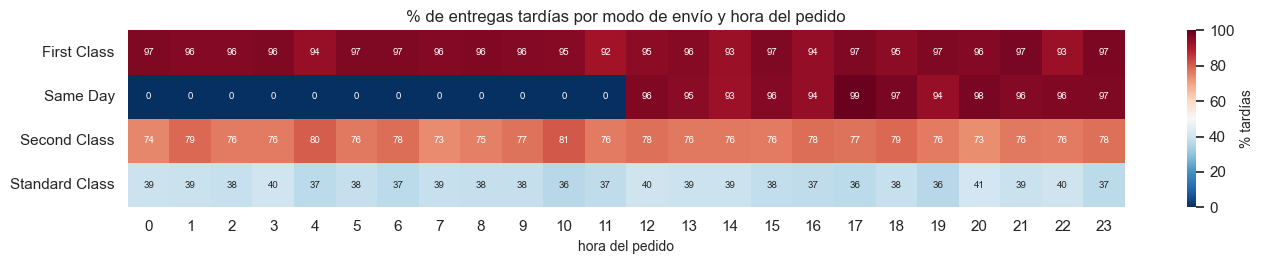

,mean_AM,mean_PM,size_AM,size_PM
shipping_mode,,,,
First Class,0.956,0.955,10517,11501
Same Day,0.000,0.959,4110,3602
Second Class,0.769,0.766,14091,13874
Standard Class,0.380,0.383,42781,42599


In [5]:
hm = train.pivot_table(index="shipping_mode", columns="order_hour", values=TARGET, aggfunc="mean")
fig, ax = plt.subplots(figsize=(14, 2.8))
sns.heatmap(100 * hm, cmap="RdBu_r", vmin=0, vmax=100, annot=True, fmt=".0f", annot_kws={"size": 7}, cbar_kws={"label": "% tardías"}, ax=ax)
ax.set_xlabel("hora del pedido"); ax.set_ylabel(""); ax.set_title("% de entregas tardías por modo de envío y hora del pedido")
plt.tight_layout(); save_figure(fig, "07_hora_por_modo.png"); plt.show()
jornada = train.groupby(["shipping_mode", "order_afternoon"])[TARGET].agg(["mean", "size"]).unstack()
jornada.columns = [f"{a}_{'PM' if b else 'AM'}" for a, b in jornada.columns]
jornada.to_csv(TABLES / "tasa_modo_jornada.csv")
display(jornada.round(3))

**Interpretación.** El efecto de la hora **no** es general: existe solo en **Same Day**. Los
pedidos Same Day hechos **antes de las 12:00** casi nunca llegan tarde y los hechos **desde
las 12:00** casi siempre llegan tarde: es una **hora de corte** operativa (el despacho del
mismo día ya salió). En Standard y Second Class la hora no influye, y **First Class** llega
tarde prácticamente siempre, a cualquier hora. Ambas variables (modo y hora) se conocen al
crear el pedido, así que este patrón **no es fuga**: es la señal más útil del EDA temporal.
**Consecuencia para el modelado:** un modelo aditivo (modo + hora) no puede representar un
efecto de la hora que solo existe en un modo; se crea la interacción `mode_x_daypart`
(modo × jornada AM/PM).

## Descomposición STL

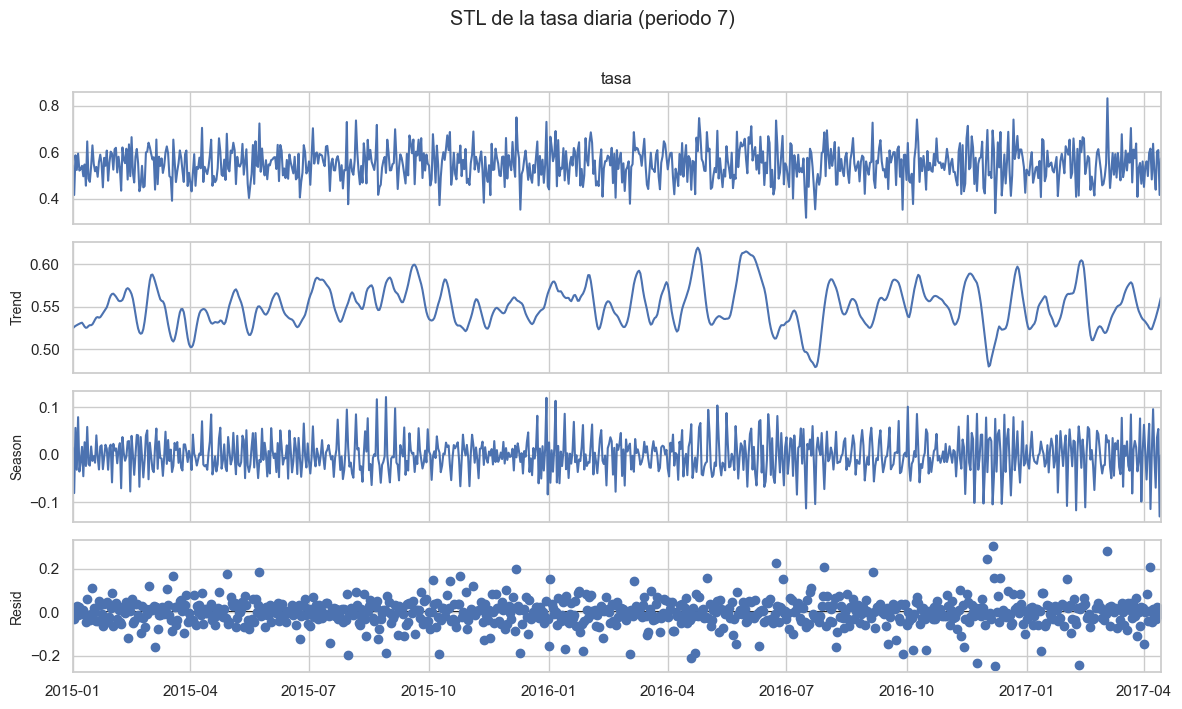

Fuerza de la tendencia = **0,110**; fuerza de la estacionalidad semanal = **0,227** (0 = nada, 1 = domina; Hyndman y Athanasopoulos, 2021, cap. 6). Ambas son bajas: STL siempre extrae algún patrón del ruido, y la prueba de Kruskal-Wallis por día de la semana no lo confirma.

In [6]:
serie = diario["tasa"].interpolate()
stl = STL(serie, period=7, robust=True).fit()
fig = stl.plot(); fig.set_size_inches(12, 7); fig.suptitle("STL de la tasa diaria (periodo 7)", y=1.01)
plt.tight_layout(); save_figure(fig, "07_stl.png"); plt.show()
fuerza_tend = max(0, 1 - np.var(stl.resid) / np.var(stl.trend + stl.resid))
fuerza_est = max(0, 1 - np.var(stl.resid) / np.var(stl.seasonal + stl.resid))
md_out(f"Fuerza de la tendencia = **{es(fuerza_tend, 3)}**; fuerza de la estacionalidad semanal = **{es(fuerza_est, 3)}** "
       "(0 = nada, 1 = domina; Hyndman y Athanasopoulos, 2021, cap. 6). Ambas son bajas: STL siempre extrae algún patrón del ruido, "
       "y la prueba de Kruskal-Wallis por día de la semana no lo confirma.")

## Estacionariedad: medias y varianzas móviles, ADF y KPSS

ADF: H₀ = raíz unitaria (no estacionaria). KPSS: H₀ = estacionaria. La conclusión es
firme cuando ambas coinciden.

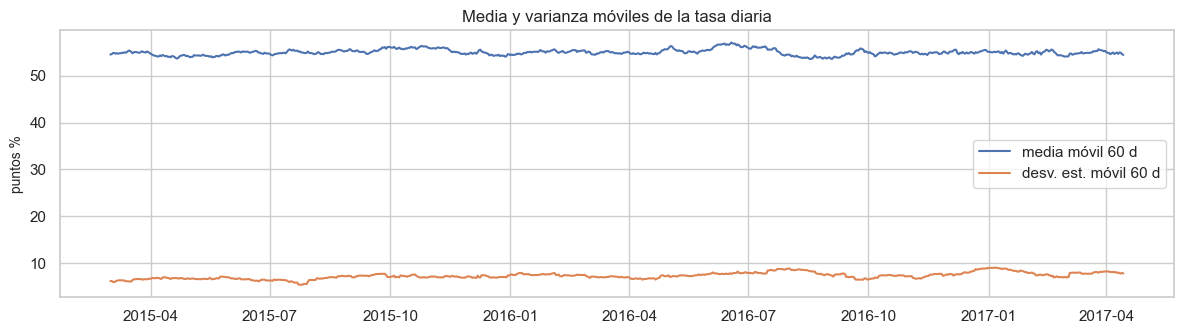

,serie,ADF estadístico,ADF p,KPSS estadístico,KPSS p,conclusión
0,tasa diaria de tardías,-21.5872,0.0,0.0466,0.1,estacionaria
1,líneas por día,-28.7777,0.0,0.0567,0.1,estacionaria


In [7]:
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(100 * serie.rolling(60).mean(), label="media móvil 60 d"); ax.plot(100 * serie.rolling(60).std(), label="desv. est. móvil 60 d")
ax.legend(); ax.set_ylabel("puntos %"); ax.set_title("Media y varianza móviles de la tasa diaria")
plt.tight_layout(); save_figure(fig, "07_moviles.png"); plt.show()
filas = []
for nombre, s in [("tasa diaria de tardías", serie), ("líneas por día", diario["lineas"].interpolate())]:
    adf = adfuller(s, autolag="AIC"); kp = kpss(s, regression="c", nlags="auto")
    filas.append({"serie": nombre, "ADF estadístico": adf[0], "ADF p": adf[1], "KPSS estadístico": kp[0], "KPSS p": kp[1],
                  "conclusión": "estacionaria" if adf[1] < 0.05 and kp[1] > 0.05 else "revisar"})
estac = pd.DataFrame(filas)
estac.to_csv(TABLES / "estacionariedad.csv", index=False)
display(estac.round(4))

## Dependencia temporal: ACF, PACF y correlación cruzada

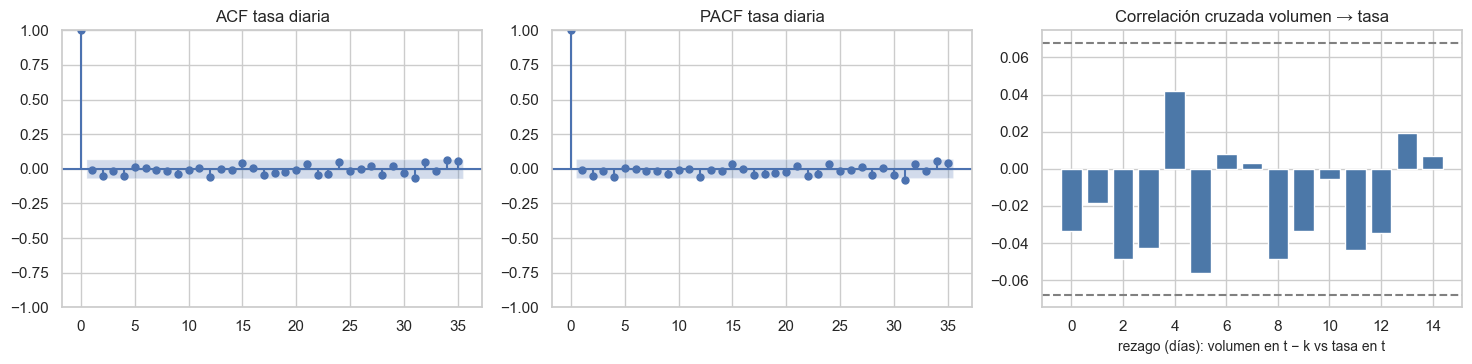

,lb_stat,lb_pvalue
7,5.2689,0.6272
14,9.4708,0.7998
28,22.3339,0.7656


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
plot_acf(serie, lags=35, ax=axes[0]); axes[0].set_title("ACF tasa diaria")
plot_pacf(serie, lags=35, ax=axes[1], method="ywm"); axes[1].set_title("PACF tasa diaria")
vol = diario["lineas"].interpolate()
cc = ccf((vol - vol.mean()) / vol.std(), (serie - serie.mean()) / serie.std(), adjusted=False, nlags=15)
axes[2].bar(range(len(cc)), cc, color="#4c78a8"); axes[2].axhline(1.96 / np.sqrt(len(serie)), ls="--", color="gray"); axes[2].axhline(-1.96 / np.sqrt(len(serie)), ls="--", color="gray")
axes[2].set_xlabel("rezago (días): volumen en t − k vs tasa en t"); axes[2].set_title("Correlación cruzada volumen → tasa")
plt.tight_layout(); save_figure(fig, "07_acf_pacf_ccf.png"); plt.show()
lb = acorr_ljungbox(serie, lags=[7, 14, 28], return_df=True)
lb.to_csv(TABLES / "ljung_box_tasa.csv")
display(lb.round(4))

**Interpretación.** La tasa diaria se comporta como **ruido blanco**: ACF y PACF dentro
de las bandas y Ljung-Box sin rechazo. La carga del día o de días previos **no**
anticipa la tasa de retrasos (correlación cruzada dentro de las bandas). ADF y KPSS
coinciden en que la serie es **estacionaria**. Consecuencia: los rezagos del objetivo no
aportarían información; la variable de carga `orders_prev_7d` se conserva solo como
control (construida con el pasado).

## Cambios de régimen, puntos de cambio y efectos de calendario

,lineas,pedidos,productos,tasa,lineas_por_pedido
order_date,,,,,
2016-09,5160,1730,54,0.550,2.983
2016-10,5398,1776,54,0.548,3.039
2016-11,5210,1721,54,0.546,3.027
2016-12,5269,1763,54,0.561,2.989
2017-01,5217,1745,54,0.536,2.990
2017-02,4906,1614,54,0.547,3.040
2017-03,5347,1782,54,0.553,3.001
2017-04,2405,815,54,0.539,2.951


,periodo,líneas,tardía_%
0,± 1 día de festivo federal de EE. UU.,11689,55.01
1,resto,131386,54.89
2,temporada alta (23-nov a 31-dic),13429,54.94
3,fuera de temporada alta,129646,54.90


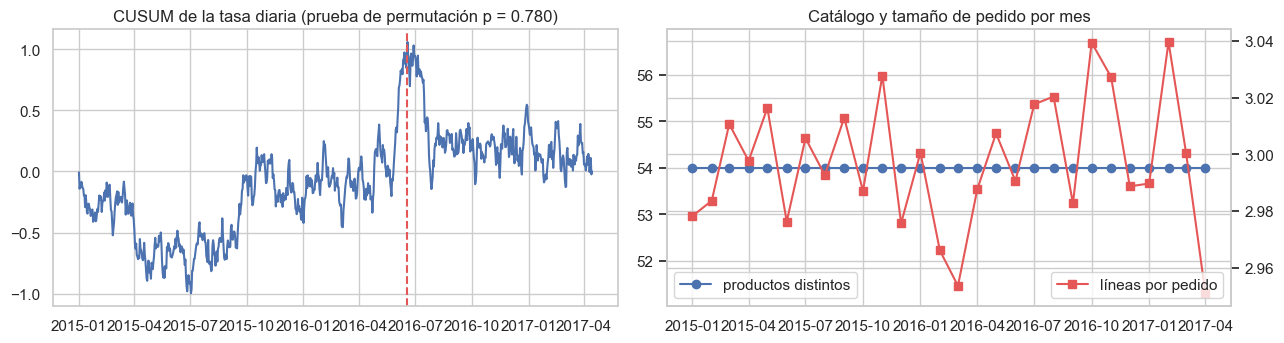

Máximo del CUSUM en 2016-06-18; p de permutación = 0.780 → **no hay evidencia de un cambio de nivel** en la tasa.

In [9]:
mens = train.groupby(d.dt.to_period("M")).agg(lineas=(TARGET, "size"), pedidos=(ORDER_COL, "nunique"),
                                             productos=("product_name", "nunique"), tasa=(TARGET, "mean"))
mens["lineas_por_pedido"] = mens["lineas"] / mens["pedidos"]
display(mens.tail(8).round(3))

# CUSUM de la tasa diaria: un cambio de nivel aparece como un quiebre de pendiente.
cusum = (serie - serie.mean()).cumsum()
k_cp = int(np.argmax(np.abs(cusum.to_numpy())))
rng = np.random.default_rng(RANDOM_STATE)
rango_obs = cusum.max() - cusum.min()
rangos = [np.ptp(np.cumsum(rng.permutation(serie.to_numpy() - serie.mean()))) for _ in range(999)]
p_cusum = (1 + np.sum(np.array(rangos) >= rango_obs)) / 1000

hol = USFederalHolidayCalendar().holidays(d.min(), d.max())
cerca = d.dt.normalize().isin(set(hol) | set(hol - pd.Timedelta(days=1)) | set(hol + pd.Timedelta(days=1)))
bf = (d.dt.month == 11) & (d.dt.day >= 23) | (d.dt.month == 12) & (d.dt.day <= 31)
cal = pd.DataFrame([
    {"periodo": "± 1 día de festivo federal de EE. UU.", "líneas": int(cerca.sum()), "tardía_%": 100 * y[cerca].mean()},
    {"periodo": "resto", "líneas": int((~cerca).sum()), "tardía_%": 100 * y[~cerca].mean()},
    {"periodo": "temporada alta (23-nov a 31-dic)", "líneas": int(bf.sum()), "tardía_%": 100 * y[bf].mean()},
    {"periodo": "fuera de temporada alta", "líneas": int((~bf).sum()), "tardía_%": 100 * y[~bf].mean()},
])
cal.to_csv(TABLES / "efectos_calendario.csv", index=False)
display(cal.round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
axes[0].plot(cusum.index, cusum.values); axes[0].axvline(cusum.index[k_cp], color="#e45756", ls="--")
axes[0].set_title(f"CUSUM de la tasa diaria (prueba de permutación p = {p_cusum:.3f})")
axes[1].plot(mens.index.to_timestamp(), mens["productos"], "o-", label="productos distintos")
ax2 = axes[1].twinx(); ax2.plot(mens.index.to_timestamp(), mens["lineas_por_pedido"], "s-", color="#e45756", label="líneas por pedido")
axes[1].set_title("Catálogo y tamaño de pedido por mes"); axes[1].legend(loc="lower left"); ax2.legend(loc="lower right")
plt.tight_layout(); save_figure(fig, "07_regimen.png"); plt.show()
md_out(f"Máximo del CUSUM en {cusum.index[k_cp]:%Y-%m-%d}; p de permutación = {p_cusum:.3f} "
       + ("→ **no hay evidencia de un cambio de nivel** en la tasa." if p_cusum > 0.05 else "→ posible cambio de nivel; revisar."))

**Interpretación.** En el entrenamiento la tasa **no** presenta cambios de nivel
(CUSUM no significativo), y los festivos de EE. UU. y la temporada de fin de año no
alteran la proporción de retrasos. El catálogo (54 productos) y el tamaño medio del
pedido (≈ 3 líneas) son estables en el entrenamiento. En el archivo completo, la ficha y
el volumen mensual muestran que **desde octubre de 2017 cada pedido tiene una sola
línea** y el catálogo se reduce: ese periodo cae en la prueba y se trata como **deriva
esperada de las covariables** (se evalúa en el cap. 11, sin usar la prueba para decidir).

## Deriva temporal dentro del entrenamiento (*covariate shift* y *concept drift*)

Se compara el primer año (2015) con el último tramo del entrenamiento (desde 2016-07):
**PSI** para las covariables (< 0,1 estable; 0,1–0,25 moderada; > 0,25 fuerte) y la tasa de
tardías **por modo de envío** en cada trimestre (cambio en P(y | x)).

,variable,PSI,nivel
2,market,5.9968,fuerte
11,orders_prev_7d,0.0519,estable
5,product_name,0.0019,estable
1,payment_type,0.0008,estable
4,category_name,0.0007,estable
6,sales,0.0004,estable
7,order_item_quantity,0.0004,estable
9,order_item_profit_ratio,0.0003,estable
12,order_hour,0.0002,estable
3,customer_segment,0.0002,estable


El PSI de `market` es enorme. La tabla de líneas por trimestre y mercado lo explica:

market,Africa,Europe,LATAM,Pacific Asia,USCA
order_date,,,,,
2015Q1,0,0,15413,0,0
2015Q2,0,5255,10362,0,0
2015Q3,0,15712,0,0,0
2015Q4,0,3947,0,11961,0
2016Q1,0,0,0,15421,0
2016Q2,0,0,0,159,15294
2016Q3,3071,983,0,1959,9786
2016Q4,7285,2889,0,5102,601
2017Q1,1258,563,12493,1038,118


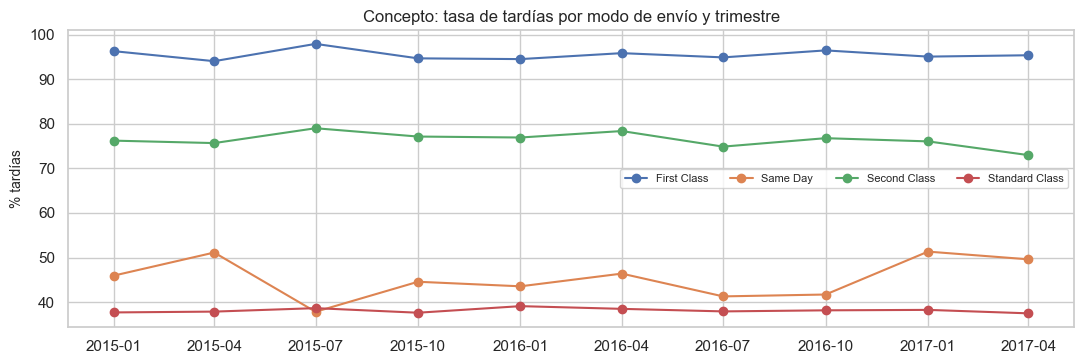

Rango (máx − mín) de la tasa trimestral por modo, en puntos porcentuales: First Class: 3,9, Same Day: 13,5, Second Class: 6,0, Standard Class: 1,6.

In [10]:
temprano, tardio = train[d < "2016-01-01"], train[d >= "2016-07-01"]
cols_psi = {"shipping_mode": True, "payment_type": True, "market": True, "customer_segment": True, "category_name": True,
            "product_name": True, "sales": False, "order_item_quantity": False, "order_item_discount_rate": False,
            "order_item_profit_ratio": False, "items_in_order": False, "orders_prev_7d": False, "order_hour": False}
deriva = pd.DataFrame([{"variable": c, "PSI": psi(temprano[c], tardio[c], categorical=cat)} for c, cat in cols_psi.items()])
deriva["nivel"] = pd.cut(deriva["PSI"], [-1, 0.1, 0.25, 99], labels=["estable", "moderada", "fuerte"])
deriva.to_csv(TABLES / "deriva_psi_train.csv", index=False)
display(deriva.sort_values("PSI", ascending=False).round(4))

md_out("El PSI de `market` es enorme. La tabla de líneas por trimestre y mercado lo explica:")
mq = pd.crosstab(d.dt.to_period("Q"), train["market"])
mq.to_csv(TABLES / "mercado_por_trimestre.csv")
display(mq)

trim = train.groupby([d.dt.to_period("Q"), "shipping_mode"])[TARGET].mean().unstack()
fig, ax = plt.subplots(figsize=(11, 3.8))
for c in trim.columns:
    ax.plot(trim.index.to_timestamp(), 100 * trim[c], "o-", label=c)
ax.set_ylabel("% tardías"); ax.set_title("Concepto: tasa de tardías por modo de envío y trimestre"); ax.legend(fontsize=8, ncol=4)
plt.tight_layout(); save_figure(fig, "07_concept_drift.png"); plt.show()
rango = (trim.max() - trim.min()) * 100
md_out("Rango (máx − mín) de la tasa trimestral por modo, en puntos porcentuales: " + ", ".join(f"{k}: {es(v, 1)}" for k, v in rango.items()) + ".")

**Interpretación.**

- **Covariate shift fuerte en el destino:** los mercados **se turnan en el tiempo** (2015-T1
  solo LATAM, 2015-T3 solo Europa, 2016-T1 solo Pacific Asia, 2016-T2 sobre todo USCA...). Es un
  artefacto de la simulación: el destino del pedido es casi una función de la fecha. Por
  eso mercado, región y país de destino **confunden geografía con tiempo** (cap. 8) y la
  prueba tendrá una mezcla de mercados distinta de la del entrenamiento reciente.
- El resto de covariables es **estable** (PSI < 0,1).
- **Concept drift:** la tasa de tardías por modo de envío es estable entre trimestres
  (Standard y First Class varían pocos puntos; Same Day, el modo con menos casos, varía más
  por tamaño de muestra). La relación entre el modo y el objetivo no cambia.

## Panel: series por entidad (mercado de destino)

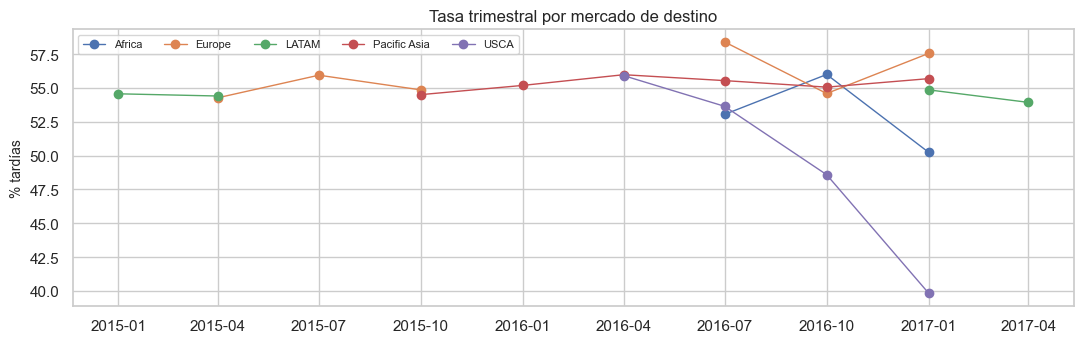

Heterogeneidad entre mercado × trimestre: χ² = 70,7 (22 g.l.), p = 0.000. Desviación estándar media entre series en un mismo trimestre: 2,21 puntos porcentuales.

In [11]:
pm = train.groupby([d.dt.to_period("Q"), "market"])[TARGET].mean().unstack()
fig, ax = plt.subplots(figsize=(11, 3.6))
for c in pm.columns:
    ax.plot(pm.index.to_timestamp(), 100 * pm[c], "o-", label=c, lw=1)
ax.set_ylabel("% tardías"); ax.set_title("Tasa trimestral por mercado de destino"); ax.legend(fontsize=8, ncol=5)
plt.tight_layout(); save_figure(fig, "07_panel_mercado.png"); plt.show()
tab = pd.crosstab([d.dt.to_period("Q"), train["market"]], y)
chi2, p_het, dof, _ = stats.chi2_contingency(tab)
pm.to_csv(TABLES / "tasa_mercado_trimestre.csv")
md_out(f"Heterogeneidad entre mercado × trimestre: χ² = {es(chi2, 1)} ({dof} g.l.), p = {p_het:.3f}. "
       f"Desviación estándar media entre series en un mismo trimestre: {es(100 * pm.std(axis=1).mean(), 2)} puntos porcentuales.")

**Interpretación.** Las series por mercado se solapan poco en el tiempo (cada mercado
aparece en ventanas distintas) y, cuando coinciden, sus tasas son parecidas. La
heterogeneidad detectada por χ² se concentra en celdas pequeñas (por ejemplo, USCA en
2017-T1 con ≈ 100 líneas). No hay evidencia de que un mercado sea sistemáticamente más
lento.

## Consecuencias para el modelado e interpretación

- **Partición cronológica**, nunca aleatoria (cap. 1): entrenamiento hasta 2017-04-14,
  *gap* de 7 días y prueba desde 2017-04-22.
- **Validación cruzada** con ventana creciente y *gap* de 7 días (`temporal_folds`, la
  versión en días de `TimeSeriesSplit(gap=…)`): el *gap* evita usar pedidos cuya etiqueta aún
  no se conocería y cubre la dependencia de corto plazo.
- **Ingeniería de características** solo con información del momento del pedido o del
  pasado: interacción **modo × jornada** (corte del mediodía en Same Day), componentes
  cíclicos de hora, día y mes (seno/coseno), indicador de fin de semana y carga de pedidos de
  los 7 días previos (ventana cerrada a la izquierda). No se usan rezagos del objetivo: la ACF muestra
  que no aportan, y requerirían etiquetas que llegan con retraso.
- **Interpretación:** sin tendencia ni estacionalidad en la tasa, proceso estable y sin
  deriva de concepto en el entrenamiento; único patrón temporal: la hora de corte del
  mediodía en los envíos Same Day. Los
  riesgos son la **rotación de mercados en el tiempo** (geografía de destino confundida con
  el periodo) y el **cambio de régimen de finales de 2017** (pedidos de una línea), que
  afectan a las covariables de la prueba.